<a href="https://colab.research.google.com/github/francisco-mreina/olist-Predict-Insatisfaction-and-delay/blob/main/06_segmentacion_clientes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis de clientes Olist (Brazilian E-Commerce)

## 8. Scoring y segmentación de actores — Problemas 3 y 4

### 8.2. Segmentación de clientes (RFM + K-Means)

Para el problema 4 se segmenta a los clientes (`customer_unique_id`) por valor y comportamiento de compra. Como se documentó en el capítulo 2.3, la tasa de recompra real es muy baja (~3,5 % de clientes con más de un pedido), por lo que un RFM clásico —muy dependiente de la frecuencia histórica— generaría clusters poco discriminantes. Se combina por tanto la lógica RFM (recencia, frecuencia, monetario) con variables de comportamiento de compra (ticket medio, peso del flete, diversidad de categorías), siguiendo el mismo patrón de `scree_plot_kmeans` + `biplot` usado en las prácticas de Minería de Datos.

In [ ]:
fecha_referencia = orders_analytical['order_purchase_timestamp'].max()

customer_level = orders_analytical.groupby('customer_unique_id').agg(
    n_pedidos=('order_id', 'nunique'),
    valor_total=('total_payment', 'sum'),
    ticket_medio=('ticket_medio_item', 'mean'),
    pct_flete_medio=('pct_flete', 'mean'),
    n_categorias_distintas=('categoria_principal', 'nunique'),
    ultima_compra=('order_purchase_timestamp', 'max'),
).reset_index()

customer_level['recencia_dias'] = (fecha_referencia - customer_level['ultima_compra']).dt.days

print(customer_level.shape)
customer_level.describe()

(96096, 8)


,n_pedidos,valor_total,ticket_medio,pct_flete_medio,n_categorias_distintas,ultima_compra,recencia_dias
count,96096.000000,96096.000000,95420.000000,95420.000000,96096.000000,96096,96096.000000
mean,1.034809,166.592492,126.555747,0.208492,1.010823,2018-01-02 12:40:19.655864832,287.735691
min,1.000000,0.000000,0.850000,0.000000,0.000000,2016-09-04 21:15:19,0.000000
25%,1.000000,63.120000,42.900000,0.116622,1.000000,2017-09-15 09:04:17.249999872,163.000000
50%,1.000000,108.000000,79.445000,0.183256,1.000000,2018-01-21 19:39:16,268.000000
75%,1.000000,183.530000,139.900000,0.274677,1.000000,2018-05-06 20:14:49.750000128,397.000000
max,17.000000,13664.080000,6735.000000,0.955451,5.000000,2018-10-17 17:30:18,772.000000
std,0.214384,231.428332,191.751327,0.125019,0.165396,NaN,153.414676


In [ ]:
#Ajustamos la función de scree_plot_kmeans del archivo de nuestras funciones para evitar excesivos valores para la RAM
# Cremos función scree_plot_kmeans para buscar el número de clusters óptimo
# con 3 métricas usuales. Wss, silueta y % de varianza explicada
# Input: data = dataset en bruto (se escala dentro de la propia función)
#        n_max = número máximo de grupos a evaluar
# ==============================================================================

def scree_plot_kmeans(data,n_max):
  range_n_clusters = range(2, n_max)
  X_scaled = scale(data)
  inertias = []
  silhouette = []

  for n_clusters in range_n_clusters:
      modelo_kmeans = KMeans(
                          n_clusters   = n_clusters,
                          n_init       = 20,
                          random_state = 123
                      )
      modelo_kmeans.fit(X_scaled)
      cluster_labels = modelo_kmeans.fit_predict(X_scaled)
      inertias.append(modelo_kmeans.inertia_)
      silhouette.append(silhouette_score(X_scaled, cluster_labels, sample_size=5000, random_state=123)
      )
  fig, ax = plt.subplots(1, 3, figsize=(16, 6))
  ax[0].plot(range_n_clusters, inertias, marker='o')
  ax[0].set_title("Scree plot Varianza intra")
  ax[0].set_xlabel('Número clusters')
  ax[0].set_ylabel('Intra-cluster (inertia)')

  ax[1].plot(range_n_clusters, silhouette, marker='o')
  ax[1].set_title("Scree plot silhouette")
  ax[1].set_xlabel('Número clusters')
  ax[1].set_ylabel('Media índices silhouette');

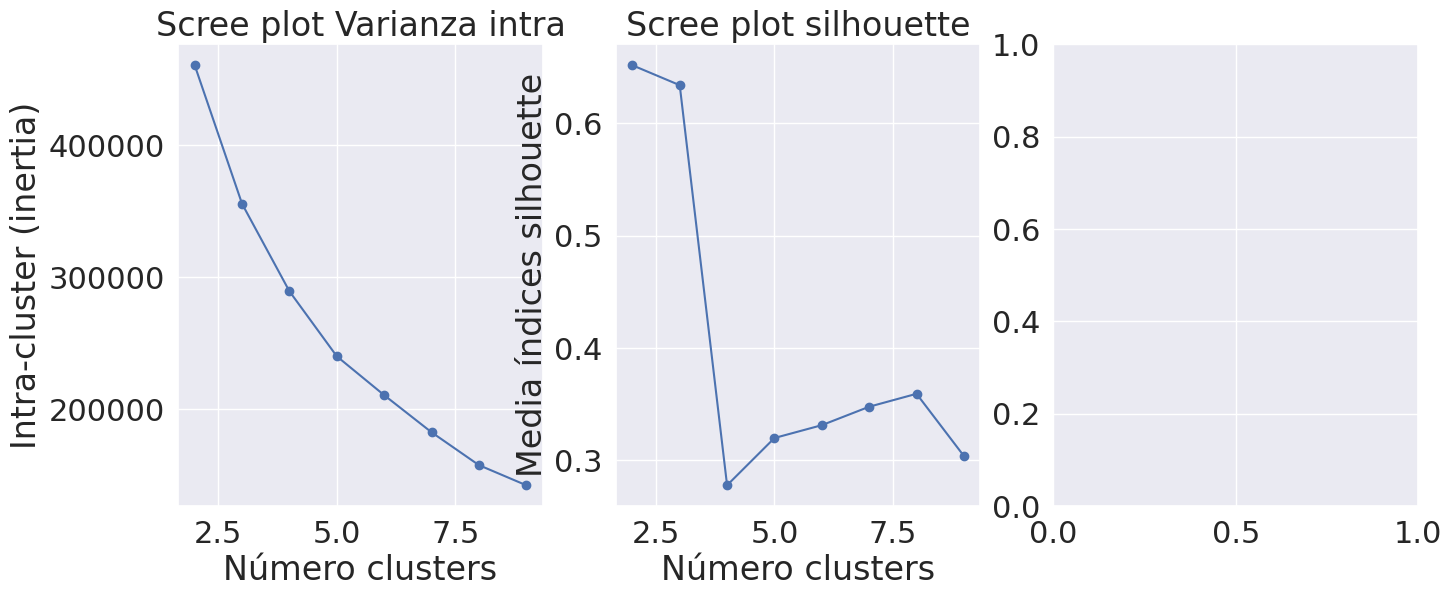

In [ ]:
rfm_vars = ['recencia_dias', 'n_pedidos', 'valor_total', 'ticket_medio',
            'pct_flete_medio', 'n_categorias_distintas']

X_rfm = customer_level[rfm_vars].fillna(0)

# Búsqueda del número óptimo de clusters (wss, silhouette, % varianza explicada)
scree_plot_kmeans(X_rfm, 10)

In [ ]:
k_optimo = 3

X_rfm_scaled = scale(X_rfm)

kmeans_clientes = KMeans(n_clusters=k_optimo, n_init=20, random_state=123)
customer_level['segmento'] = kmeans_clientes.fit_predict(X_rfm_scaled)

customer_level['segmento'].value_counts().sort_index()

,count
segmento,
0,90824
1,3588
2,1684


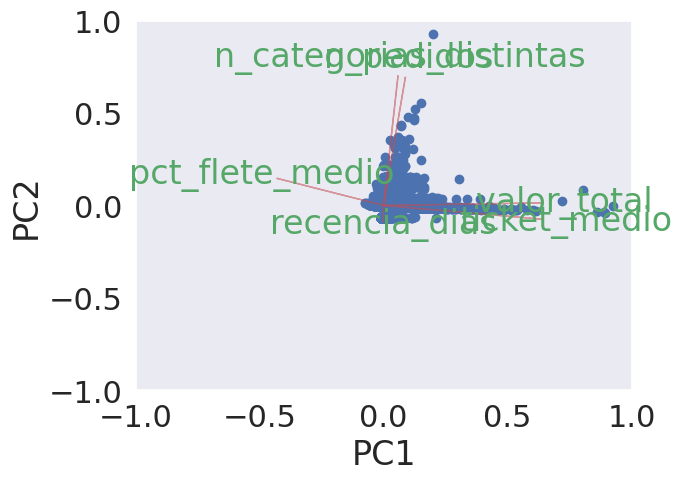

Varianza explicada por los 2 primeros componentes: 0.6367045133646049


In [ ]:
# Biplot: proyección de los clientes y de las variables RFM sobre los 2 primeros componentes
pca_clientes = PCA(n_components=2)
scores_clientes = pca_clientes.fit_transform(X_rfm_scaled)

biplot(scores_clientes[:, 0:2], np.transpose(pca_clientes.components_[0:2, :]), rfm_vars)
plt.show()

print('Varianza explicada por los 2 primeros componentes:',
      pca_clientes.explained_variance_ratio_.sum())

### 8.3. Caracterización de segmentos

Se describe cada segmento en términos de las variables RFM originales (sin escalar), para poder interpretarlo en lenguaje de negocio en el capítulo 11.

In [ ]:
resumen_segmentos = customer_level.groupby('segmento')[rfm_vars].mean().round(2)
resumen_segmentos['n_clientes'] = customer_level.groupby('segmento').size()
resumen_segmentos['pct_clientes'] = (resumen_segmentos['n_clientes'] / customer_level.shape[0] * 100).round(1)

resumen_segmentos

,recencia_dias,n_pedidos,valor_total,ticket_medio,pct_flete_medio,n_categorias_distintas,n_clientes,pct_clientes
segmento,,,,,,,,
0,288.35,1.01,131.21,98.48,0.21,0.99,90824,94.5
1,289.23,1.02,995.49,846.78,0.06,0.99,3588,3.7
2,251.60,2.20,308.67,105.35,0.22,2.02,1684,1.8


In [ ]:
# Visualización del perfil de cada segmento (valor medio del pedido, mismo estilo que en 6.2)
fig = px.bar(
    resumen_segmentos.reset_index(),
    x='segmento', y='valor_total',
    color='valor_total',
    template='plotly_white',
    color_continuous_scale='Blues',
    title='Valor total medio por segmento de cliente'
)
fig.show()